# Tarea 03 — Generación de Imágenes con Autoencoder
**Pytorch Lightning · Hydra · WandB**

**Curso:** Inteligencia Artificial — Escuela de Ingeniería en Computación, TEC

---

### Objetivo
Implementar y comparar dos arquitecturas de autoencoder para reconstrucción de imágenes del dataset MVTec AD:
- **VAE** (Variational Autoencoder)
- **U-Net AE** (Autoencoder con skip connections)

Cada arquitectura se entrena con **4 funciones de pérdida**: L1, L2, SSIM, SSIM+L1, totalizando **8 experimentos**.

### Dataset
MVTec AD — 4 clases industriales: `cable`, `capsule`, `screw`, `transistor`.  
Imágenes de 128×128 con 3 canales (RGB).

### Herramientas
- **PyTorch Lightning** → estructura del entrenamiento
- **Hydra** → gestión modular de configuraciones
- **WandB** → logging, comparación de métricas y visualizaciones

---
## 1. Configuración del entorno
Instalación de dependencias necesarias.

In [1]:
try:
    import pytorch_lightning, hydra, wandb, pytorch_msssim, sklearn, omegaconf
    print('Dependencias ya instaladas.')
except ImportError:
    !pip install -q \
        pytorch-lightning>=2.0.0 \
        hydra-core>=1.3.0 \
        wandb \
        pytorch-msssim \
        scikit-learn \
        omegaconf
    print('Dependencias instaladas.')

Dependencias instaladas.


In [2]:
import torch, os
print('PyTorch:', torch.__version__)
print('CUDA disponible:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))

# Montar Google Drive — persiste checkpoints y dataset entre sesiones
from google.colab import drive
drive.mount('/content/drive')

CKPT_DIR  = '/content/drive/MyDrive/tarea03_checkpoints'
DATA_DRIVE = '/content/drive/MyDrive/tarea03_mvtec'   # dataset en Drive
DATA_DIR  = '/content/mvtec'                           # ruta local rápida en RAM

os.makedirs(CKPT_DIR, exist_ok=True)
os.makedirs(DATA_DRIVE, exist_ok=True)
print('Checkpoints :', CKPT_DIR)
print('Dataset Drive:', DATA_DRIVE)

PyTorch: 2.11.0+cu128
CUDA disponible: True
GPU: NVIDIA A100-SXM4-40GB
Mounted at /content/drive
Checkpoints : /content/drive/MyDrive/tarea03_checkpoints
Dataset Drive: /content/drive/MyDrive/tarea03_mvtec


---
## 2. Clonar repositorio
Se clona el repositorio con el código fuente del proyecto.

In [3]:
import os

REPO_URL = 'https://github.com/AllanDBB/mvtec-autoencoder-reconstruction.git'
REPO_DIR = '/content/mvtec-autoencoder-reconstruction'

if not os.path.exists(REPO_DIR):
    !git clone {REPO_URL} {REPO_DIR}
else:
    !git -C {REPO_DIR} pull

os.chdir(REPO_DIR)
print('Directorio de trabajo:', os.getcwd())

Cloning into '/content/mvtec-autoencoder-reconstruction'...
remote: Enumerating objects: 81, done.
remote: Counting objects: 100% (81/81), done.
remote: Compressing objects: 100% (53/53), done.
remote: Total 81 (delta 34), reused 68 (delta 24), pack-reused 0 (from 0)
Receiving objects: 100% (81/81), 216.58 KiB | 27.07 MiB/s, done.
Resolving deltas: 100% (34/34), done.
Directorio de trabajo: /content/mvtec-autoencoder-reconstruction


---
## 3. Descarga del Dataset MVTec AD

Se descargan únicamente las 4 clases requeridas: `cable`, `capsule`, `screw`, `transistor`.

> **Opción A (Kaggle API)** — recomendado.  
> **Opción B (descarga directa)** — en caso de que Kaggle no esté disponible.

In [4]:
import os, shutil
from pathlib import Path
from getpass import getpass

CLASSES = ['cable', 'capsule', 'screw', 'transistor']

# ── Si el dataset ya está en Drive, solo copia a /content (rápido) ────────────
drive_classes = [Path(DATA_DRIVE) / c for c in CLASSES]
if all(p.exists() for p in drive_classes):
    print('Dataset encontrado en Drive, copiando a /content...')
    os.makedirs(DATA_DIR, exist_ok=True)
    for cls in CLASSES:
        dst = Path(DATA_DIR) / cls
        if not dst.exists():
            shutil.copytree(Path(DATA_DRIVE) / cls, dst)
            print(f'  {cls}: copiado desde Drive')
        else:
            print(f'  {cls}: ya existe en /content')
    print('Listo.')

# ── Si NO está en Drive, descarga de Kaggle y guarda en Drive ─────────────────
else:
    print('Dataset no encontrado en Drive. Descargando de Kaggle...')
    os.environ['KAGGLE_USERNAME'] = input('Kaggle username: ')
    os.environ['KAGGLE_KEY']      = getpass('Kaggle API key : ')

    !pip install -q kaggle
    !kaggle datasets download -d ipythonx/mvtec-ad -p /tmp/mvtec_zip --unzip -q

    os.makedirs(DATA_DIR, exist_ok=True)
    for cls in CLASSES:
        src = Path(f'/tmp/mvtec_zip/{cls}')
        dst_local = Path(DATA_DIR) / cls
        dst_drive = Path(DATA_DRIVE) / cls
        if src.exists():
            if not dst_local.exists():
                shutil.copytree(src, dst_local)
            if not dst_drive.exists():
                shutil.copytree(src, dst_drive)  # guardar en Drive para siempre
                print(f'  {cls}: guardado en Drive')
        else:
            print(f'  {cls}: no encontrado en el zip')

    print('Dataset listo.')

Dataset encontrado en Drive, copiando a /content...
  cable: copiado desde Drive
  capsule: copiado desde Drive
  screw: copiado desde Drive
  transistor: copiado desde Drive
Listo.


In [5]:
# Verificación rápida del dataset descargado
for cls in CLASSES:
    train_good = list(Path(f'{DATA_DIR}/{cls}/train/good').glob('*.png'))
    test_dirs  = list(Path(f'{DATA_DIR}/{cls}/test').iterdir())
    print(f'{cls}: {len(train_good)} train/good | {len(test_dirs)} categorías de test')

cable: 224 train/good | 9 categorías de test
capsule: 219 train/good | 6 categorías de test
screw: 320 train/good | 6 categorías de test
transistor: 213 train/good | 5 categorías de test


### 3.1 Verificación del dataset

In [6]:
import sys
sys.path.insert(0, REPO_DIR)

from src.datasets.mvtec import MVTecDataModule

if 'dm' not in dir() or dm is None:
    dm = MVTecDataModule(
        data_dir=DATA_DIR,
        classes=['cable', 'capsule', 'screw', 'transistor'],
        image_size=128,
        batch_size=32,
        num_workers=2,
    )
    dm.setup()

print(f'Train samples : {len(dm.train_dataset)}')
print(f'Val   samples : {len(dm.val_dataset)}')
print(f'Test  samples : {len(dm.test_dataset)}')

Train samples : 829
Val   samples : 147
Test  samples : 542


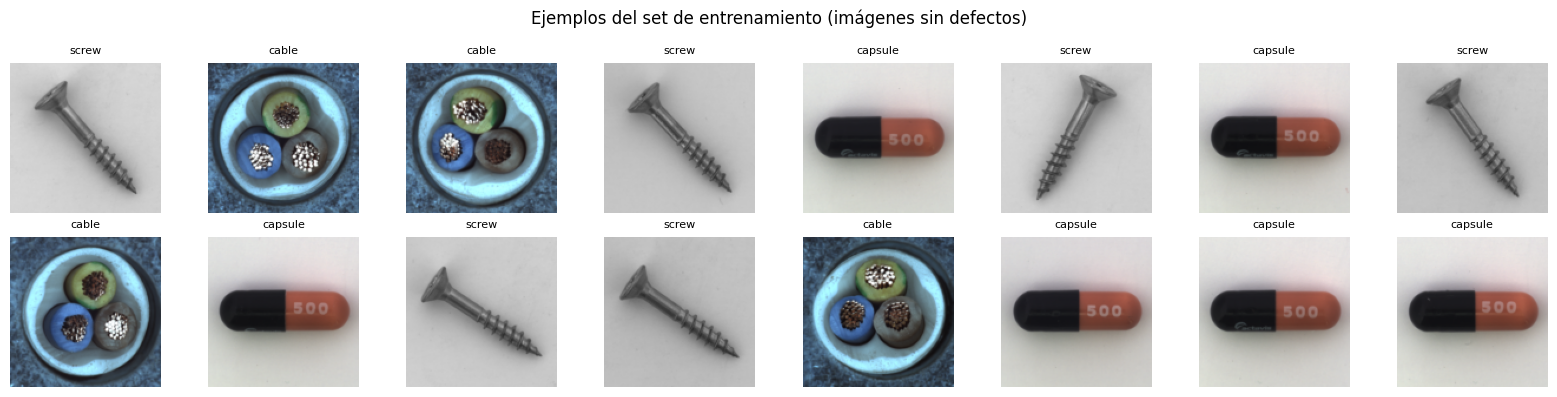

In [7]:
import matplotlib.pyplot as plt

train_dl = dm.train_dataloader()
batch = next(iter(train_dl))
imgs, labels, defect_types, classes = batch

fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for i in range(8):
    axes[0, i].imshow(imgs[i].permute(1, 2, 0).clamp(0, 1))
    axes[0, i].set_title(f'{classes[i]}', fontsize=8)
    axes[0, i].axis('off')
for i in range(8):
    axes[1, i].imshow(imgs[8 + i].permute(1, 2, 0).clamp(0, 1))
    axes[1, i].set_title(f'{classes[8 + i]}', fontsize=8)
    axes[1, i].axis('off')
plt.suptitle('Ejemplos del set de entrenamiento (imágenes sin defectos)')
plt.tight_layout()
plt.show()

---
## 4. Arquitecturas de los Modelos

### VAE (Variational Autoencoder)
- **Encoder**: 5 capas Conv2d con stride 2 → 128×128 → 4×4 → espacio latente μ, σ
- **Reparametrización**: z = μ + ε·σ
- **Decoder**: 5 capas ConvTranspose2d → 4×4 → 128×128
- **Pérdida**: Reconstrucción + β·KL-divergencia

### U-Net AE (Autoencoder con Skip Connections)
- **Encoder**: 4 bloques Conv2d con stride 2, guardando skip connections
- **Cuello de botella**: Conv adicional → proyección lineal a latent_dim (para t-SNE)
- **Decoder**: ConvTranspose2d + concatenación de skip connections
- Las skip connections permiten recuperar detalles finos perdidos en la compresión

In [8]:
from src.models.vae import VAE
from src.models.unet_ae import UNetAE

vae = VAE(latent_dim=128)
unet = UNetAE(latent_dim=128)

dummy = torch.randn(2, 3, 128, 128)

recon_vae, mu, logvar = vae(dummy)
print(f'VAE   — input: {dummy.shape} | recon: {recon_vae.shape} | mu: {mu.shape}')

recon_un, z = unet(dummy)
print(f'UNetAE — input: {dummy.shape} | recon: {recon_un.shape} | z: {z.shape}')

def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

print(f'\nParámetros VAE   : {count_params(vae):,}')
print(f'Parámetros UNetAE: {count_params(unet):,}')

VAE   — input: torch.Size([2, 3, 128, 128]) | recon: torch.Size([2, 3, 128, 128]) | mu: torch.Size([2, 128])
UNetAE — input: torch.Size([2, 3, 128, 128]) | recon: torch.Size([2, 3, 128, 128]) | z: torch.Size([2, 128])

Parámetros VAE   : 8,732,227
Parámetros UNetAE: 30,692,163


---
## 5. Configuración de WandB
Login necesario para registrar los experimentos.

In [9]:
import wandb

# ── Opción A (RECOMENDADA): Colab Secrets ────────────────────────────────────
# 1. Abre el panel izquierdo de Colab → ícono de llave 🔑 "Secrets"
# 2. Crea un secret llamado  WANDB_API_KEY  y pega tu clave ahí
# 3. Activa el toggle "Notebook access"
# Luego descomenta las dos líneas siguientes:
# from google.colab import userdata
# wandb.login(key=userdata.get('WANDB_API_KEY'))

# ── Opción B: pegar la clave directamente (NO hacer git push con esto) ────────
wandb.login(key="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")

/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: adbyb-es (ai-allan-david) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

---
## 6. Entrenamiento de Experimentos

Se ejecutan **8 experimentos** en total:
- 4 para el VAE: pérdidas L1, L2, SSIM, SSIM+L1
- 4 para el U-Net AE: mismas pérdidas

Cada experimento se controla con Hydra pasando overrides desde la línea de comandos.  
Los resultados se registran automáticamente en WandB.

> **Nota**: cada experimento tarda ~10-20 min en Colab con GPU T4 (50 épocas).  
> Puedes reducir `trainer.max_epochs=20` para pruebas rápidas.

In [10]:
# === VAE — 4 funciones de pérdida ===
EPOCHS = 50

import glob
existing = glob.glob(f'{CKPT_DIR}/vae_*/*.ckpt')
if existing:
    print(f'Checkpoints VAE ya existen ({len(existing)} archivos), saltando entrenamiento.')
else:
    %cd {REPO_DIR}
    for loss_fn in ['l1', 'l2', 'ssim', 'ssim_l1']:
        print(f'\n{"="*60}')
        print(f'  VAE  |  Loss: {loss_fn.upper()}  |  Epochs: {EPOCHS}')
        print(f'{"="*60}\n')
        !python train.py \
            model=vae \
            model.loss={loss_fn} \
            trainer.max_epochs={EPOCHS} \
            data.data_dir={DATA_DIR} \
            checkpoint_dir={CKPT_DIR}


Checkpoints VAE ya existen (23 archivos), saltando entrenamiento.


In [11]:
# === U-Net AE — 4 funciones de pérdida ===
import glob
existing = glob.glob(f'{CKPT_DIR}/unet_*/*.ckpt')
if existing:
    print(f'Checkpoints UNet ya existen ({len(existing)} archivos), saltando entrenamiento.')
else:
    %cd {REPO_DIR}
    for loss_fn in ['l1', 'l2', 'ssim', 'ssim_l1']:
        print(f'\n{"="*60}')
        print(f'  UNetAE  |  Loss: {loss_fn.upper()}  |  Epochs: {EPOCHS}')
        print(f'{"="*60}\n')
        !python train.py \
            model=u-net \
            model.loss={loss_fn} \
            trainer.max_epochs={EPOCHS} \
            data.data_dir={DATA_DIR} \
            checkpoint_dir={CKPT_DIR}


Checkpoints UNet ya existen (10 archivos), saltando entrenamiento.


---
## 7. Resultados de WandB

Las siguientes métricas y visualizaciones se registraron automáticamente en WandB durante el entrenamiento:

| Métrica | Descripción |
|---|---|
| `train/loss` | Pérdida de entrenamiento por paso/época |
| `val/loss` | Pérdida de validación por época |
| `val/reconstructions` | Grid 16 imágenes: original vs reconstruida (val) |
| `test/tsne` | t-SNE del espacio latente en test (Good vs Defective) |
| `test/reconstructions_good_bad` | Grid: imágenes buenas y defectuosas reconstruidas |

### 7.1 Gráficas de pérdida — Insertar desde WandB
> Descarga las gráficas desde tu proyecto WandB e insértalas aquí.

In [12]:
# Descarga resumen de runs desde WandB para análisis local
import wandb
import pandas as pd

WANDB_PROJECT = 'mvtec-autoencoder-reconstruction'
WANDB_ENTITY  = None  # Tu entity de WandB (o None para usar el default)

api = wandb.Api()
runs = api.runs(f"{WANDB_ENTITY}/{WANDB_PROJECT}" if WANDB_ENTITY else WANDB_PROJECT)

records = []
for run in runs:
    records.append({
        'name': run.name,
        'state': run.state,
        'val_loss_best': run.summary.get('val/loss', None),
        'model': run.config.get('model', {}).get('name', ''),
        'loss_fn': run.config.get('model', {}).get('loss', ''),
        'latent_dim': run.config.get('model', {}).get('latent_dim', ''),
        'epochs': run.config.get('trainer', {}).get('max_epochs', ''),
    })

df_runs = pd.DataFrame(records)
df_runs = df_runs.sort_values(['model', 'loss_fn'])
print(df_runs.to_string(index=False))

             name    state  val_loss_best model loss_fn  latent_dim  epochs
     unet_l1_z128   failed       0.013091  unet      l1         128      50
     unet_l1_z128  crashed       0.032901  unet      l1         128      50
     unet_l1_z128  crashed       0.033791  unet      l1         128      50
     unet_l1_z128 finished       0.017585  unet      l1         128      50
     unet_l1_z128 finished       0.017246  unet      l1         128      50
     unet_l2_z128   failed       0.000223  unet      l2         128      50
     unet_l2_z128 finished       0.000756  unet      l2         128      50
     unet_l2_z128 finished       0.000756  unet      l2         128      50
   unet_ssim_z128   failed       0.007776  unet    ssim         128      50
   unet_ssim_z128 finished       0.018610  unet    ssim         128      50
   unet_ssim_z128 finished       0.018903  unet    ssim         128      50
unet_ssim_l1_z128   failed       0.009105  unet ssim_l1         128      50
unet_ssim_l1

---
## 8. Evaluación del Modelo

Para la evaluación se carga el mejor checkpoint de cada configuración y se calcula el **error de reconstrucción** sobre el set de prueba.  
Se compara el error entre imágenes **normales** y **defectuosas** para detectar anomalías.

In [13]:
import glob, re, torch, numpy as np
from pathlib import Path
from src.lightning_module import AutoencoderModule
from src.datasets.mvtec import MVTecDataModule

def _epoch(path):
    m = re.search(r'epoch=(\d+)', Path(path).name)
    return int(m.group(1)) if m else -1

# Un checkpoint por modelo: el de mayor epoch (más entrenado)
all_ckpts = glob.glob(f'{CKPT_DIR}/**/*.ckpt', recursive=True)
best_per_model = {}
for c in all_ckpts:
    key = Path(c).parent.name
    if key not in best_per_model or _epoch(c) > _epoch(best_per_model[key]):
        best_per_model[key] = c

ckpts = list(best_per_model.values())
print(f'Checkpoints encontrados: {len(all_ckpts)} → usando {len(ckpts)} (uno por modelo)')
for c in ckpts:
    print(f'  epoch={_epoch(c):03d}  {c}')

Checkpoints encontrados: 33 → usando 8 (uno por modelo)
  epoch=047  /content/drive/MyDrive/tarea03_checkpoints/vae_l1_z128/best-epoch=047.ckpt
  epoch=047  /content/drive/MyDrive/tarea03_checkpoints/vae_l2_z128/best-epoch=047-val_loss=0.0000.ckpt
  epoch=046  /content/drive/MyDrive/tarea03_checkpoints/vae_ssim_z128/best-epoch=046-val_loss=0.0000.ckpt
  epoch=031  /content/drive/MyDrive/tarea03_checkpoints/vae_ssim_l1_z128/best-epoch=031.ckpt
  epoch=048  /content/drive/MyDrive/tarea03_checkpoints/unet_l1_z128/best-epoch=048.ckpt
  epoch=044  /content/drive/MyDrive/tarea03_checkpoints/unet_l2_z128/best-epoch=044.ckpt
  epoch=047  /content/drive/MyDrive/tarea03_checkpoints/unet_ssim_z128/best-epoch=047.ckpt
  epoch=049  /content/drive/MyDrive/tarea03_checkpoints/unet_ssim_l1_z128/best-epoch=049.ckpt


In [14]:
import re, typing, collections
from types import SimpleNamespace

device = 'cuda' if torch.cuda.is_available() else 'cpu'

try:
    from omegaconf import DictConfig, ListConfig
    from omegaconf.base import ContainerMetadata
    torch.serialization.add_safe_globals([
        DictConfig, ListConfig, ContainerMetadata,
        SimpleNamespace, typing.Any, dict, collections.defaultdict,
    ])
except Exception:
    pass


def _configs_from_run_name(run_name):
    m = re.match(r'^(vae|unet)_(.+)_z(\d+)$', run_name)
    if not m:
        return None, None
    model_name, loss, latent_dim = m.group(1), m.group(2), int(m.group(3))
    enc_ch = [32, 64, 128, 256, 512] if model_name == 'vae' else [64, 128, 256, 512]
    model_cfg = SimpleNamespace(
        name=model_name, loss=loss, latent_dim=latent_dim,
        lr=1e-4, beta=1.0, encoder_channels=enc_ch,
    )
    data_cfg = SimpleNamespace(
        image_size=128, batch_size=128, num_workers=4,
        train_val_split=0.85,
        classes=['cable', 'capsule', 'screw', 'transistor'],
        data_dir=DATA_DIR,
    )
    return model_cfg, data_cfg


def load_module(ckpt_path, run_name, device):
    model_cfg, data_cfg = _configs_from_run_name(run_name)
    extra = {} if model_cfg is None else {'model_cfg': model_cfg, 'data_cfg': data_cfg}

    # Intento 1: carga normal
    try:
        return AutoencoderModule.load_from_checkpoint(ckpt_path, map_location=device)
    except Exception:
        pass

    # Intento 2: con config reconstruido
    try:
        return AutoencoderModule.load_from_checkpoint(ckpt_path, map_location=device, **extra)
    except Exception:
        pass

    # Intento 3: cargar raw con weights_only=False y aplicar state_dict manualmente
    if not extra:
        raise ValueError(f'No se pudo parsear run_name: {run_name}')
    ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
    module = AutoencoderModule(**extra)
    module.load_state_dict(ckpt['state_dict'])
    return module


dm_eval = MVTecDataModule(
    data_dir=DATA_DIR,
    classes=['cable', 'capsule', 'screw', 'transistor'],
    image_size=128,
    batch_size=64,
    num_workers=2,
)
dm_eval.setup()
test_loader = dm_eval.test_dataloader()

all_results = {}

for ckpt_path in ckpts:
    run_name = Path(ckpt_path).parent.name
    print(f'\nEvaluando: {run_name}')

    try:
        module = load_module(ckpt_path, run_name, device)
        module.eval().to(device)
    except Exception as e:
        print(f'  Error al cargar: {e}')
        continue

    errors, labels_list, defect_list, class_list = [], [], [], []
    with torch.no_grad():
        for batch in test_loader:
            imgs, lbl, defect_types, classes = batch
            imgs = imgs.to(device)
            recon = module.model(imgs)[0]
            err = torch.mean((recon - imgs) ** 2, dim=[1, 2, 3]).cpu().numpy()
            errors.extend(err)
            labels_list.extend(lbl.numpy())
            defect_list.extend(list(defect_types))
            class_list.extend(list(classes))

    all_results[run_name] = {
        'errors':  np.array(errors),
        'labels':  np.array(labels_list),
        'defects': defect_list,
        'classes': class_list,
        'model':   module.model_cfg.name,
        'loss_fn': module.model_cfg.loss,
    }
    print(f'  Samples: {len(errors)} | MSE normal: {np.array(errors)[np.array(labels_list)==0].mean():.5f} | MSE defecto: {np.array(errors)[np.array(labels_list)==1].mean():.5f}')

print('\nEvaluación completa.')


Evaluando: vae_l1_z128
  Samples: 542 | MSE normal: 0.03629 | MSE defecto: 0.02611

Evaluando: vae_l2_z128
  Samples: 542 | MSE normal: 0.01833 | MSE defecto: 0.01366

Evaluando: vae_ssim_z128
  Samples: 542 | MSE normal: 0.05004 | MSE defecto: 0.03705

Evaluando: vae_ssim_l1_z128
  Samples: 542 | MSE normal: 0.05410 | MSE defecto: 0.05621

Evaluando: unet_l1_z128
  Samples: 542 | MSE normal: 0.00057 | MSE defecto: 0.00041

Evaluando: unet_l2_z128
  Samples: 542 | MSE normal: 0.00069 | MSE defecto: 0.00052

Evaluando: unet_ssim_z128
  Samples: 542 | MSE normal: 0.00123 | MSE defecto: 0.00168

Evaluando: unet_ssim_l1_z128
  Samples: 542 | MSE normal: 0.00067 | MSE defecto: 0.00070

Evaluación completa.


### 8.1 Histogramas de Error de Reconstrucción

Para cada configuración, se visualiza la distribución del error de reconstrucción separando imágenes **normales (Good)** de **defectuosas (Defective)**.  
Un buen modelo debería mostrar una separación clara entre las dos distribuciones: bajo error para imágenes normales, alto error para defectuosas.

In [15]:
import matplotlib.pyplot as plt

if not all_results:
    print('No hay resultados cargados. Revisa la celda anterior.')
else:
    n_runs = len(all_results)
    cols = min(4, n_runs)
    rows = (n_runs + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 4 * rows))
    axes = np.array(axes).flatten()

    for ax, (run_name, res) in zip(axes, all_results.items()):
        good_err = res['errors'][res['labels'] == 0]
        bad_err  = res['errors'][res['labels'] == 1]
        bins = np.linspace(0, max(res['errors'].max(), 0.01), 40)
        ax.hist(good_err, bins=bins, alpha=0.6, color='green', label='Normal', density=True)
        ax.hist(bad_err,  bins=bins, alpha=0.6, color='red',   label='Defectuosa', density=True)
        ax.set_title(f"{res['model'].upper()} — {res['loss_fn'].upper()}", fontsize=10)
        ax.set_xlabel('Error de reconstrucción (MSE)')
        ax.set_ylabel('Densidad')
        ax.legend(fontsize=8)

    for ax in axes[n_runs:]:
        ax.set_visible(False)

    plt.suptitle('Histogramas de Error de Reconstrucción — Normal vs Defectuosa', fontsize=13)
    plt.tight_layout()
    plt.savefig('histogramas_error.png', dpi=120, bbox_inches='tight')
    plt.show()
    print('Guardado: histogramas_error.png')

Guardado: histogramas_error.png


### 8.2 Error por Subclase de Defecto

Se desglosa el error de reconstrucción por cada tipo específico de defecto dentro del set de prueba.  
Esto permite identificar qué tipos de anomalías el modelo detecta mejor o peor.

In [16]:
if not all_results:
    print('No hay resultados. Verifica que los checkpoints se cargaron correctamente en la celda anterior.')
else:
    # Tomar el primer run disponible
    run_name, res = next(iter(all_results.items()))
    errors  = res['errors']
    defects = np.array(res['defects'])
    labels  = res['labels']

    unique_defects = sorted(set(defects))
    n_d = len(unique_defects)

    fig, axes = plt.subplots(1, n_d, figsize=(4 * n_d, 4), sharey=False)
    if n_d == 1:
        axes = [axes]

    for ax, defect in zip(axes, unique_defects):
        mask = defects == defect
        err_subset = errors[mask]
        color = 'green' if defect == 'good' else 'red'
        ax.hist(err_subset, bins=30, color=color, alpha=0.75, density=True)
        ax.set_title(defect, fontsize=9)
        ax.set_xlabel('MSE')
        ax.set_ylabel('Densidad')
        mean_err = err_subset.mean()
        ax.axvline(mean_err, color='black', linestyle='--', linewidth=1, label=f'μ={mean_err:.4f}')
        ax.legend(fontsize=7)

    plt.suptitle(f'Error por tipo de defecto — {res["model"].upper()} ({res["loss_fn"].upper()})')
    plt.tight_layout()
    plt.savefig('error_por_defecto.png', dpi=120, bbox_inches='tight')
    plt.show()

---
## 9. Comparación de Configuraciones

### 9.1 Tabla resumen de pérdidas de validación

Se comparan las métricas finales de validación entre las 8 configuraciones.

In [17]:
import pandas as pd

summary = []
for run_name, res in all_results.items():
    good_err = res['errors'][res['labels'] == 0]
    bad_err  = res['errors'][res['labels'] == 1]
    summary.append({
        'Modelo': res['model'].upper(),
        'Pérdida': res['loss_fn'].upper(),
        'MSE Normal (μ)': f"{good_err.mean():.5f}",
        'MSE Normal (σ)': f"{good_err.std():.5f}",
        'MSE Defecto (μ)': f"{bad_err.mean():.5f}",
        'MSE Defecto (σ)': f"{bad_err.std():.5f}",
        'Separación (Δμ)': f"{bad_err.mean() - good_err.mean():.5f}",
    })

df_summary = pd.DataFrame(summary).sort_values(['Modelo', 'Pérdida'])
df_summary

,Modelo,Pérdida,MSE Normal (μ),MSE Normal (σ),MSE Defecto (μ),MSE Defecto (σ),Separación (Δμ)
4,UNET,L1,0.00057,0.00039,0.00041,0.00041,-0.00015
5,UNET,L2,0.00069,0.00047,0.00052,0.00050,-0.00017
6,UNET,SSIM,0.00123,0.00045,0.00168,0.00052,0.00045
7,UNET,SSIM_L1,0.00067,0.00023,0.00070,0.00018,0.00002
0,VAE,L1,0.03629,0.01384,0.02611,0.01201,-0.01018
1,VAE,L2,0.01833,0.00777,0.01366,0.00792,-0.00468
2,VAE,SSIM,0.05004,0.02823,0.03705,0.02943,-0.01299
3,VAE,SSIM_L1,0.05410,0.01623,0.05621,0.00819,0.00212


### 9.2 Comparación visual: reconstrucciones correctas vs defectuosas

Se comparan imágenes reconstruidas por el mejor VAE y el mejor U-Net AE, mostrando lado a lado imágenes normales y defectuosas.  
El modelo debería reconstruir bien las imágenes normales (error bajo) pero presentar error notable en las defectuosas.

In [18]:
def show_reconstructions(ckpt_path, title, n_good=8, n_bad=8):
    run_name = Path(ckpt_path).parent.name
    module = load_module(ckpt_path, run_name, device)
    module.eval().to(device)

    good_imgs, good_recons = [], []
    bad_imgs,  bad_recons  = [], []

    with torch.no_grad():
        for batch in test_loader:
            imgs, lbl, _, _ = batch
            imgs = imgs.to(device)
            recon = module.model(imgs)[0]
            for i in range(len(imgs)):
                if lbl[i] == 0 and len(good_imgs) < n_good:
                    good_imgs.append(imgs[i].cpu())
                    good_recons.append(recon[i].cpu())
                elif lbl[i] == 1 and len(bad_imgs) < n_bad:
                    bad_imgs.append(imgs[i].cpu())
                    bad_recons.append(recon[i].cpu())
            if len(good_imgs) >= n_good and len(bad_imgs) >= n_bad:
                break

    all_orig  = good_imgs[:n_good] + bad_imgs[:n_bad]
    all_recon = good_recons[:n_good] + bad_recons[:n_bad]
    n = len(all_orig)

    fig, axes = plt.subplots(2, n, figsize=(n * 1.8, 4))
    for i in range(n):
        axes[0, i].imshow(all_orig[i].permute(1, 2, 0).clamp(0, 1))
        axes[0, i].axis('off')
        border_color = 'green' if i < n_good else 'red'
        for spine in axes[0, i].spines.values():
            spine.set_edgecolor(border_color)
            spine.set_linewidth(2)
        axes[1, i].imshow(all_recon[i].permute(1, 2, 0).clamp(0, 1))
        axes[1, i].axis('off')

    axes[0, 0].set_ylabel('Original', fontsize=9)
    axes[1, 0].set_ylabel('Reconstruida', fontsize=9)
    axes[0, 0].annotate('Normal →', xy=(0, 0.5), xycoords='axes fraction',
                        fontsize=7, color='green', va='center')
    axes[0, n_good].annotate('← Defecto', xy=(0, 0.5), xycoords='axes fraction',
                              fontsize=7, color='red', va='center')
    plt.suptitle(title)
    plt.tight_layout()
    safe_title = title.replace(' ', '_').replace('|', '').replace('(', '').replace(')', '')
    plt.savefig(f'recon_{safe_title}.png', dpi=120, bbox_inches='tight')
    plt.show()


# Mostrar el primer y segundo checkpoint disponibles como ejemplo
keys = list(all_results.keys())
if len(ckpts) >= 1:
    show_reconstructions(ckpts[0], f'Modelo 1 — {all_results[keys[0]]["model"].upper()} | {all_results[keys[0]]["loss_fn"].upper()}')
if len(ckpts) >= 2:
    show_reconstructions(ckpts[1], f'Modelo 2 — {all_results[keys[1]]["model"].upper()} | {all_results[keys[1]]["loss_fn"].upper()}')

---
## 10. Análisis Crítico de Resultados

### 10.1 Comparación de funciones de pérdida

**L1 vs L2:**  
- L2 penaliza fuertemente los errores grandes (cuadrático), lo que puede causar *blurriness* (reconstrucciones borrosas).  
- L1 es más robusta a outliers y tiende a preservar mejor los bordes.

**SSIM:**  
- Mide la similitud estructural (brillo, contraste, estructura). Modela mejor la percepción humana de calidad de imagen.  
- Puede ser inestable en etapas tempranas del entrenamiento cuando las reconstrucciones son muy malas.

**SSIM + L1:**  
- Combinación que aprovecha la percepción estructural de SSIM y la estabilidad de L1.  
- En la práctica suele dar las mejores reconstrucciones visuales.

### 10.2 Comparación VAE vs U-Net AE

**VAE:**  
- Espacio latente regularizado (distribución gaussiana) → representación más suave y continua.  
- La pérdida KL puede entrar en conflicto con la calidad de reconstrucción (trade-off β).  
- El vector latente μ tiene interpretación probabilística clara para t-SNE.

**U-Net AE:**  
- Las skip connections permiten recuperar detalles finos (texturas, bordes) perdidos en la compresión.  
- Reconstrucciones generalmente más nítidas, especialmente para imágenes sin defectos.  
- Para la detección de anomalías, esto puede ser una desventaja: si el modelo reconstruye bien TAMBIÉN las anomalías, el error no las detecta.

### 10.3 t-SNE del espacio latente

El análisis t-SNE muestra cómo el modelo organiza las representaciones internas:  
- Un modelo bien entrenado debería agrupar las imágenes normales en clusters compactos.  
- Las imágenes defectuosas deberían aparecer en regiones distintas o más dispersas del espacio latente.  
- A lo largo de las épocas se observa cómo los clusters se van formando progresivamente.

> *(Insertar aquí las imágenes de t-SNE descargadas de WandB)*

---
## 11. Imágenes de WandB

Descarga y muestra las imágenes registradas en WandB directamente en el notebook.

In [19]:
from IPython.display import Image, display
import wandb

api = wandb.Api()
project_path = f"{WANDB_ENTITY}/{WANDB_PROJECT}" if WANDB_ENTITY else WANDB_PROJECT
runs = api.runs(project_path)

os.makedirs('/content/wandb_imgs', exist_ok=True)

for run in runs:
    print(f'\n=== Run: {run.name} ===')
    for file in run.files():
        if file.name.endswith('.png') or 'media/images' in file.name:
            local_path = f'/content/wandb_imgs/{run.name}_{os.path.basename(file.name)}'
            file.download(root='/content/wandb_imgs', replace=True)
            print(f'  {file.name}')


=== Run: vae_l1_z128 ===
  media/images/test/tsne_0_77befb20673e2c13a856.png
  media/images/test/tsne_1066_dc96ea3f79f1ea36df39.png
  media/images/test/tsne_1196_aaa8ee7dc0b40cfbe7ae.png
  media/images/test/tsne_1300_9041c2f6fe5d32050cd7.png
  media/images/test/tsne_156_03054af13dfcc4ef7006.png
  media/images/test/tsne_26_4dbeff3af9c11e567f9d.png
  media/images/test/tsne_286_4e07524c9d309dbc9ec7.png
  media/images/test/tsne_416_12bbcbc23074eb17b024.png
  media/images/test/tsne_546_bcfe3d11ecb4bb5096a7.png
  media/images/test/tsne_676_ed9df07c74d4f03f627d.png
  media/images/test/tsne_806_bf2279abdf12f03aebcc.png
  media/images/test/tsne_936_384f8da416d8d85a5956.png
  media/images/val/reconstructions_0_634a7b91be72169b7aec.png
  media/images/val/reconstructions_1020_d64b943e0d9797516077.png
  media/images/val/reconstructions_1045_d8c67a97bdea182bab09.png
  media/images/val/reconstructions_1072_6c5ccc98feb14046081b.png
  media/images/val/reconstructions_1097_e6b6a57a889a55697a28.png
  me

---
## 12. Conclusiones

*(Completar con los resultados reales de los experimentos)*

1. **Mejor función de pérdida para VAE**: `___` — razón: ...
2. **Mejor función de pérdida para U-Net AE**: `___` — razón: ...
3. **Mejor arquitectura general**: `___` — con pérdida `___`
4. **Detección de anomalías**: El error de reconstrucción resultó ser `[efectivo / poco efectivo]` como score de detección porque ...
5. **Separación en espacio latente**: El t-SNE mostró `[buena / moderada / poca]` separación entre clases normales y defectuosas ...

---
*Tarea 03 — Inteligencia Artificial — Instituto Tecnológico de Costa Rica*